Loading Wine Quality Dataset

Feature Shape: (6497, 11)
Target Shape : (6497, 1)

DATA CLEANING

Missing Values
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64

Duplicate Rows: 1179

Class Distribution
quality
1    3331
0    1987
Name: count, dtype: int64

Data Standardized Successfully


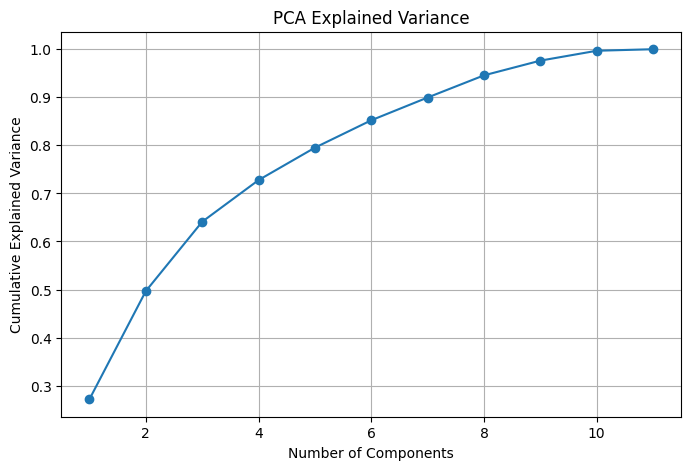


Selected Components: 9
Variance Retained: 97.63 %

Logistic Regression
Accuracy : 0.7509
Precision: 0.7706
Recall   : 0.8574
F1 Score : 0.8117

Classification Report
              precision    recall  f1-score   support

           0       0.71      0.57      0.63       398
           1       0.77      0.86      0.81       666

    accuracy                           0.75      1064
   macro avg       0.74      0.72      0.72      1064
weighted avg       0.75      0.75      0.74      1064



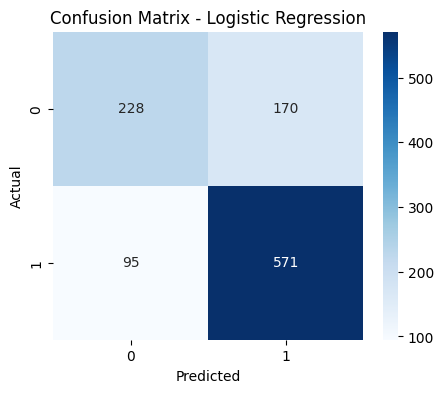


K-Nearest Neighbors
Accuracy : 0.7256
Precision: 0.7641
Recall   : 0.8123
F1 Score : 0.7875

Classification Report
              precision    recall  f1-score   support

           0       0.65      0.58      0.61       398
           1       0.76      0.81      0.79       666

    accuracy                           0.73      1064
   macro avg       0.71      0.70      0.70      1064
weighted avg       0.72      0.73      0.72      1064



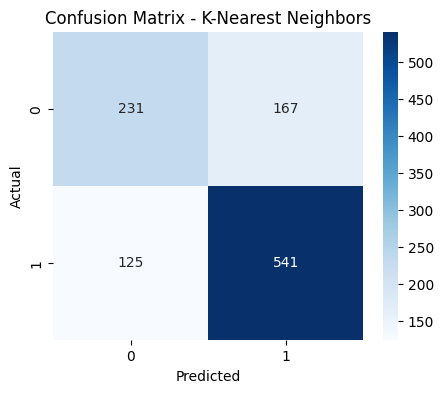


Naive Bayes
Accuracy : 0.7162
Precision: 0.7345
Recall   : 0.8559
F1 Score : 0.7906

Classification Report
              precision    recall  f1-score   support

           0       0.67      0.48      0.56       398
           1       0.73      0.86      0.79       666

    accuracy                           0.72      1064
   macro avg       0.70      0.67      0.68      1064
weighted avg       0.71      0.72      0.70      1064



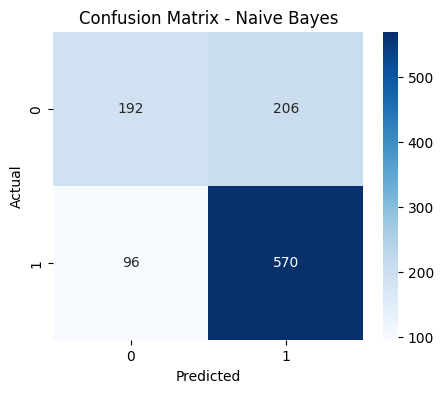



MODEL COMPARISON
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.750940   0.770580  0.857357  0.811656
1  K-Nearest Neighbors  0.725564   0.764124  0.812312  0.787482
2          Naive Bayes  0.716165   0.734536  0.855856  0.790569


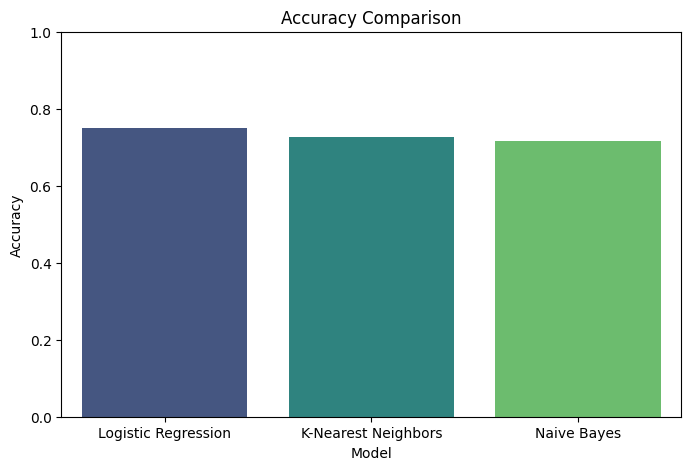

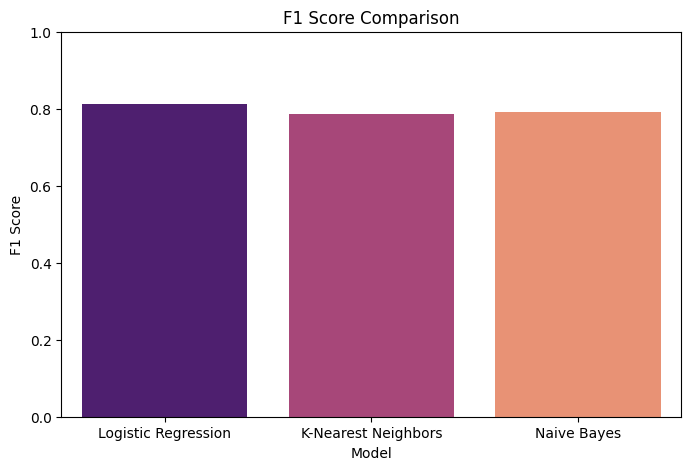



BEST PERFORMING MODEL
Model        Logistic Regression
Accuracy                 0.75094
Precision                0.77058
Recall                  0.857357
F1 Score                0.811656
Name: 0, dtype: object


METRIC EXPLANATIONS

Accuracy
- Percentage of correctly classified samples.

Precision
- Out of predicted positive wines,
  how many were actually positive.

Recall
- Out of actual positive wines,
  how many were correctly identified.

F1 Score
- Harmonic mean of Precision and Recall.
- Useful when classes are imbalanced.



PCA EXPLANATION

PCA was applied after standard scaling.

Number of selected principal components = 9

The selected components preserve at least 95%
of the original dataset variance while reducing
dimensionality.

This helps:
1. Reduce noise.
2. Reduce redundancy.
3. Improve computational efficiency.
4. Potentially improve model performance.



CONCLUSION

1. Wine Quality dataset was cleaned and standardized.

2. PCA was applied to reduce dimensionality w

In [1]:
# ==========================================================
# ASSIGNMENT 3
# Dimensionality Reduction & Classification
# Dataset: Wine Quality (UCI)
# ==========================================================

!pip install -q ucimlrepo

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# 1. Load Dataset
# ==========================================================

print("="*60)
print("Loading Wine Quality Dataset")
print("="*60)

wine = fetch_ucirepo(id=186)

X = wine.data.features
y = wine.data.targets

print("\nFeature Shape:", X.shape)
print("Target Shape :", y.shape)

# ==========================================================
# 2. Data Cleaning
# ==========================================================

print("\n" + "="*60)
print("DATA CLEANING")
print("="*60)

print("\nMissing Values")
print(X.isnull().sum())

print("\nDuplicate Rows:", X.duplicated().sum())

X = X.drop_duplicates()

# Binary Classification:
# Quality >= 6 → Good Wine (1)
# Quality < 6  → Poor Wine (0)

y = y.loc[X.index]

y = (y["quality"] >= 6).astype(int)

print("\nClass Distribution")
print(y.value_counts())

# ==========================================================
# 3. Standard Scaling
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nData Standardized Successfully")

# ==========================================================
# 4. Apply PCA
# ==========================================================

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8,5))
plt.plot(
    range(1, len(explained_variance)+1),
    explained_variance,
    marker="o"
)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True)
plt.show()

# Select enough components for 95% variance

n_components = np.argmax(
    explained_variance >= 0.95
) + 1

print("\nSelected Components:", n_components)

pca = PCA(n_components=n_components)

X_pca = pca.fit_transform(X_scaled)

print(
    "Variance Retained:",
    round(sum(pca.explained_variance_ratio_)*100,2),
    "%"
)

# ==========================================================
# 5. Train-Test Split
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ==========================================================
# 6. Model Evaluation Function
# ==========================================================

results = []

def evaluate_model(name, model):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n" + "="*60)
    print(name)
    print("="*60)

    print("Accuracy :", round(accuracy,4))
    print("Precision:", round(precision,4))
    print("Recall   :", round(recall,4))
    print("F1 Score :", round(f1,4))

    print("\nClassification Report")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# ==========================================================
# 7. Logistic Regression
# ==========================================================

log_model = LogisticRegression(max_iter=1000)

evaluate_model(
    "Logistic Regression",
    log_model
)

# ==========================================================
# 8. K-Nearest Neighbors
# ==========================================================

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

evaluate_model(
    "K-Nearest Neighbors",
    knn_model
)

# ==========================================================
# 9. Naive Bayes
# ==========================================================

nb_model = GaussianNB()

evaluate_model(
    "Naive Bayes",
    nb_model
)

# ==========================================================
# 10. Comparison Results
# ==========================================================

results_df = pd.DataFrame(results)

print("\n")
print("="*60)
print("MODEL COMPARISON")
print("="*60)

print(results_df)

# ==========================================================
# 11. Accuracy Comparison Plot
# ==========================================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    palette="viridis"
)

plt.title("Accuracy Comparison")
plt.ylim(0,1)
plt.show()

# ==========================================================
# 12. F1 Score Comparison Plot
# ==========================================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score",
    palette="magma"
)

plt.title("F1 Score Comparison")
plt.ylim(0,1)
plt.show()

# ==========================================================
# 13. Best Model
# ==========================================================

best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("\n")
print("="*60)
print("BEST PERFORMING MODEL")
print("="*60)

print(best_model)

# ==========================================================
# 14. Metric Explanations
# ==========================================================

print("\n")
print("="*60)
print("METRIC EXPLANATIONS")
print("="*60)

print("""
Accuracy
- Percentage of correctly classified samples.

Precision
- Out of predicted positive wines,
  how many were actually positive.

Recall
- Out of actual positive wines,
  how many were correctly identified.

F1 Score
- Harmonic mean of Precision and Recall.
- Useful when classes are imbalanced.
""")

# ==========================================================
# 15. PCA Explanation
# ==========================================================

print("\n")
print("="*60)
print("PCA EXPLANATION")
print("="*60)

print(f"""
PCA was applied after standard scaling.

Number of selected principal components = {n_components}

The selected components preserve at least 95%
of the original dataset variance while reducing
dimensionality.

This helps:
1. Reduce noise.
2. Reduce redundancy.
3. Improve computational efficiency.
4. Potentially improve model performance.
""")

# ==========================================================
# 16. Final Conclusion
# ==========================================================

print("\n")
print("="*60)
print("CONCLUSION")
print("="*60)

print(f"""
1. Wine Quality dataset was cleaned and standardized.

2. PCA was applied to reduce dimensionality while
   retaining approximately 95% of the variance.

3. Logistic Regression, KNN, and Naive Bayes
   classifiers were trained using PCA-transformed data.

4. Performance was evaluated using Accuracy,
   Precision, Recall, and F1 Score.

5. The best-performing model was:
   {best_model['Model']}

6. The selected model achieved the highest
   F1 Score and provided the best balance
   between precision and recall.

Therefore, {best_model['Model']} is recommended
for Wine Quality classification.
""")